**notebook for second stage data analysis on the auto-claims dataset**

First descriptive analysis was made using data-wrangler (files attached), below are my key findings:

- targets "total loss amount" and "total claim count" are very disperse with a heavy bias toward no loss/no events
- "total loss amount" has at least one atypical value (possible outlier)
- there are minimal missing values
- at least the "business type" feature needs to be normalized, will check the other categorical features
- the AL and APD classes seem to be balanced
- there are 75 duplicated policy id´s, probably duplicate values
- there are 3702 unique client id´s, will need to check correlations between the duplicated "clients" to ensure independence of observations
- the snapshot date seems to be un-correlated to the data, it is probably a system date
- from the descriptions all categorical features seem to be nominal in nature
- the "external_risk" feature seem to be uniformally distributed

**other considerations**

from the data_dictionary.md file and what I could gather from the insurance industry, the following fields need to be excluded from the final model since they are a. probably calculated using the risk factor we want to predict or b. not present at time of risk evaluation:

- claim_paid_amount_current_period
- claim_status_current_period
- days_to_first_claim_report
- deductible
- coverage_limit_000
- annual_premium
- payment_frequency

In [61]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import r_regression, f_regression, f_classif,mutual_info_regression
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdat
from matplotlib.ticker import FuncFormatter, ScalarFormatter
import seaborn as sns
import matplotlib.dates as mdates
import locale

In [62]:
#just some aesthetical settings, please disregard
category_colors = {
    "APD": "#3267ee",
    "AL": "#D5CEB5"
}

sns.set_theme(
    style="whitegrid",
    rc={
        "text.color": "#A49280"
    }
)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Frutiger', 'Frutiger Next', 'Neue Frutiger', 'Segoe UI', 'Arial', 'DejaVu Sans']


locale.getlocale()

locale.setlocale(locale.LC_TIME, 'en_US')

formatter_money_ammounts = FuncFormatter(lambda y, _: f"{y*1e-3:,.0f}K")

In [63]:
#plt.rcParams.keys()

In [64]:
pd.set_option('display.float_format', lambda x: '%.10f' % x)

For the data quality check we will use the whole training dataset, we will split it before we do any descriptive analysis

In [65]:
df_train_auto_policies = pd.read_csv("../data/train.csv")

In [66]:
#first we search the categorical features for possible formating issues
# note: counts of unique values, missing values and other basic checks were reviewed in data wrangler

categorical_features = ['coverage_type', 'business_type', 'state' ]

for col in categorical_features:
    print(df_train_auto_policies[col].unique())

['APD' 'AL']
['service' 'Trucking' 'Construction' 'Retail' 'Other' 'Service'
 'construction' 'other' 'trucking' 'SERVICE' 'TRUCKING' 'OTHER' 'RETAIL'
 'retail' 'CONSTRUCTION' 'Agriculture']
['AZ' 'TX' 'NY' 'IL' 'FL' 'OH' 'GA' 'WA' 'NC' 'CO' 'CA' 'PA']


- coverage_type dos not need any cleaning
- business_type needs to be cleaned / regularized
- state does not need any cleaning but it only has 12 of 50 expected values, noted for later

In [67]:
df_train_auto_policies['business_type'] = df_train_auto_policies['business_type'].str.lower()

we drop duplicates

In [68]:
df_train_auto_policies = df_train_auto_policies.drop_duplicates()
#df_train_auto_policies.nunique()

now we would handle missing values, but abstain of doing so due to the following observations:

- driver_avg_age has 4% of missing values but its "well distributed" so we could probably use the mean value to fill, however, age migth give us a strong signal and doing so could affect our model so we reserve judgment until after the analysis
- prior_year_mileage_000 has 6% off missing values and is heavily skewed, we will leave it as is
- prior_loss_amount has 8% of missing values, we could fill missing values with 0 only if both the prior ADP and AL counts are both 0, however having a missing ammount could just as easly mean that the record has no previous history, so it will stay as is

so we move on

Now we look for insigths in our data, first we will transform the date policy_expiration_date year/month as a stand in for temporal analysis and will calculate the same binary target used in the model draft, then we will check for:
- patterns across time for each target
- behavior patterns by feature
- correlations between features and potential targets
- redundancies in our features
- potential synergies between features for feature engineering


some important considerations:
- we will have to analyze the relation between the claim_count and the average total_loss_amount per claim, an in-depth explanation of why will be given in the README.md file and in the presentation
- for the sake of brevity all findings will be discused in the presentation and will not be explained here, brief explanations of why we will be using each test will be given in comments



In [69]:
#we transform the dates to numeric values and create the had_claim target
#during data analysis I found records from befor 2020-07 seem to be incomplete so we will clean them (only two records)
df_train_auto_policies['policy_expiration_date'] = pd.to_datetime(df_train_auto_policies['policy_expiration_date'])
df_train_auto_policies['policy_expiration_date_year_month_numeric'] = df_train_auto_policies['policy_expiration_date'].dt.year + (df_train_auto_policies['policy_expiration_date'].dt.month - 1) / 12
df_train_auto_policies['policy_expiration_date_year_month_period'] = df_train_auto_policies['policy_expiration_date'].dt.to_period('M')

df_train_auto_policies['policy_effective_date'] = pd.to_datetime(df_train_auto_policies['policy_effective_date'])
df_train_auto_policies['policy_effective_date_year_month_numeric'] = df_train_auto_policies['policy_effective_date'].dt.year + (df_train_auto_policies['policy_effective_date'].dt.month - 1) / 12
df_train_auto_policies['policy_effective_date_year_month_period'] = df_train_auto_policies['policy_effective_date'].dt.to_period('M')

df_train_auto_policies["had_claim_binary"] = (df_train_auto_policies["claim_count"] > 0).astype(int)

df_train_auto_policies = df_train_auto_policies[df_train_auto_policies["policy_expiration_date"] >= '2020-07-01']

df_train_auto_policies = df_train_auto_policies.drop(columns=["policy_expiration_date", "policy_effective_date"])

# we also create the total_loss/claim_count metric target

df_train_auto_policies['avg_loss'] = np.where(
    df_train_auto_policies['had_claim_binary'] <= 1, df_train_auto_policies['total_loss_amount'],df_train_auto_policies['total_loss_amount']/df_train_auto_policies['claim_count'])


In [70]:
# crate the df for whole dataset claim ratio 
df_train_auto_policies['had_claim_binary_0'] = df_train_auto_policies['had_claim_binary'] == 0
df_train_auto_policies['had_claim_binary_1'] = df_train_auto_policies['had_claim_binary'] == 1

claims_ym = df_train_auto_policies.groupby(['policy_expiration_date_year_month_period']).agg(
    no_claim_count = ('had_claim_binary_0', 'sum'),
    had_claim_count = ('had_claim_binary_1', 'sum'),
    claim_count = ('claim_count', 'sum'),
    policies_count = ('policy_id', 'count')
).reset_index()

claims_ym['had_claim_ratio'] = claims_ym['had_claim_count'] / claims_ym['no_claim_count']
claims_ym['claim_ratio'] = claims_ym['claim_count'] / claims_ym['no_claim_count']

claims_ym = claims_ym.drop(columns=['no_claim_count', 'had_claim_count'])

# crate the df for coverage claim ratio 

claims_ym_byCoverage = df_train_auto_policies.groupby(['policy_expiration_date_year_month_period','coverage_type']).agg(
    no_claim_count = ('had_claim_binary_0', 'sum'),
    had_claim_count = ('had_claim_binary_1', 'sum'),
    claim_count = ('claim_count', 'sum'),
    policies_count = ('policy_id', 'count')
).reset_index()

claims_ym_byCoverage['had_claim_ratio'] = claims_ym_byCoverage['had_claim_count'] / claims_ym_byCoverage['no_claim_count']
claims_ym_byCoverage['claim_ratio'] = claims_ym_byCoverage['claim_count'] / claims_ym_byCoverage['no_claim_count']

claims_ym_byCoverage = claims_ym_byCoverage.drop(columns=['no_claim_count', 'had_claim_count'])

#print(claims_ym)

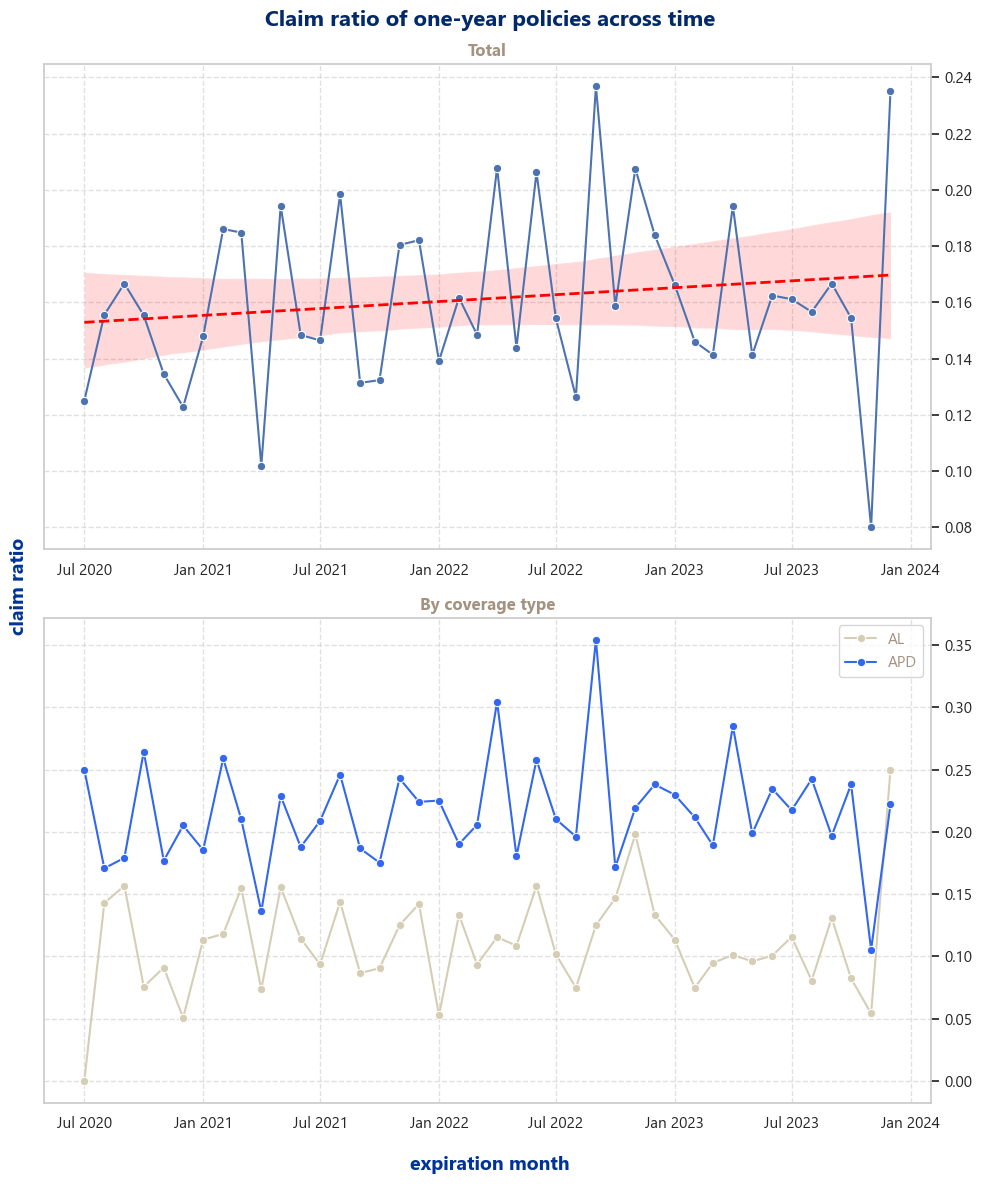

In [71]:
claims_ym['policy_expiration_date_year_month_period'] = claims_ym['policy_expiration_date_year_month_period'].dt.to_timestamp()

min_date_complete = claims_ym["policy_expiration_date_year_month_period"].min()
max_date_complete = claims_ym["policy_expiration_date_year_month_period"].max()

fig, ax = plt.subplots(2, 1, figsize=(10, 12))

sns.lineplot(data = claims_ym, x="policy_expiration_date_year_month_period", 
             y="claim_ratio", ax=ax[0], marker="o")
sns.regplot(
    x=mdates.date2num(claims_ym["policy_expiration_date_year_month_period"]),
    y=claims_ym["claim_ratio"],
    ax=ax[0],
    scatter=False,
    color="red",
    label="Trendline",
    line_kws={"linestyle": "--", "linewidth": 2}
)
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[0].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax[0].tick_params(axis='x', rotation=0) 
#ax[0].set_xlim(min_date_complete, max_date_complete)
ax[0].set_xlabel('')
ax[0].set_ylabel('')
ax[0].set_title("Total",fontsize=12, fontweight='bold', color = '#A49280')
ax[0].grid(True, linestyle="--", alpha = 0.6)
ax[0].yaxis.tick_right()



claims_ym_byCoverage['policy_expiration_date_year_month_period'] = claims_ym_byCoverage['policy_expiration_date_year_month_period'].dt.to_timestamp()

sns.lineplot(data = claims_ym_byCoverage, x="policy_expiration_date_year_month_period", 
             y="claim_ratio", hue="coverage_type",palette= category_colors, ax=ax[1], marker="o")

ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax[1].tick_params(axis='x', rotation=0) 
#ax[1].set_xlim(min_date_complete, max_date_complete)
ax[1].set_xlabel('')
ax[1].set_ylabel('')
ax[1].set_title("By coverage type",fontsize=12, fontweight='bold', color = '#A49280')
ax[1].grid(True, linestyle="--", alpha = 0.6)
ax[1].yaxis.tick_right()

fig.suptitle("Claim ratio of one-year policies across time", fontsize=16, fontweight='bold', color = '#02296A')
fig.supxlabel("expiration month", fontsize=14 ,fontweight='bold', color = '#003399')
fig.supylabel("claim ratio", fontsize=14, fontweight='bold', color = '#003399')


plt.legend()
plt.tight_layout()

plt.show()








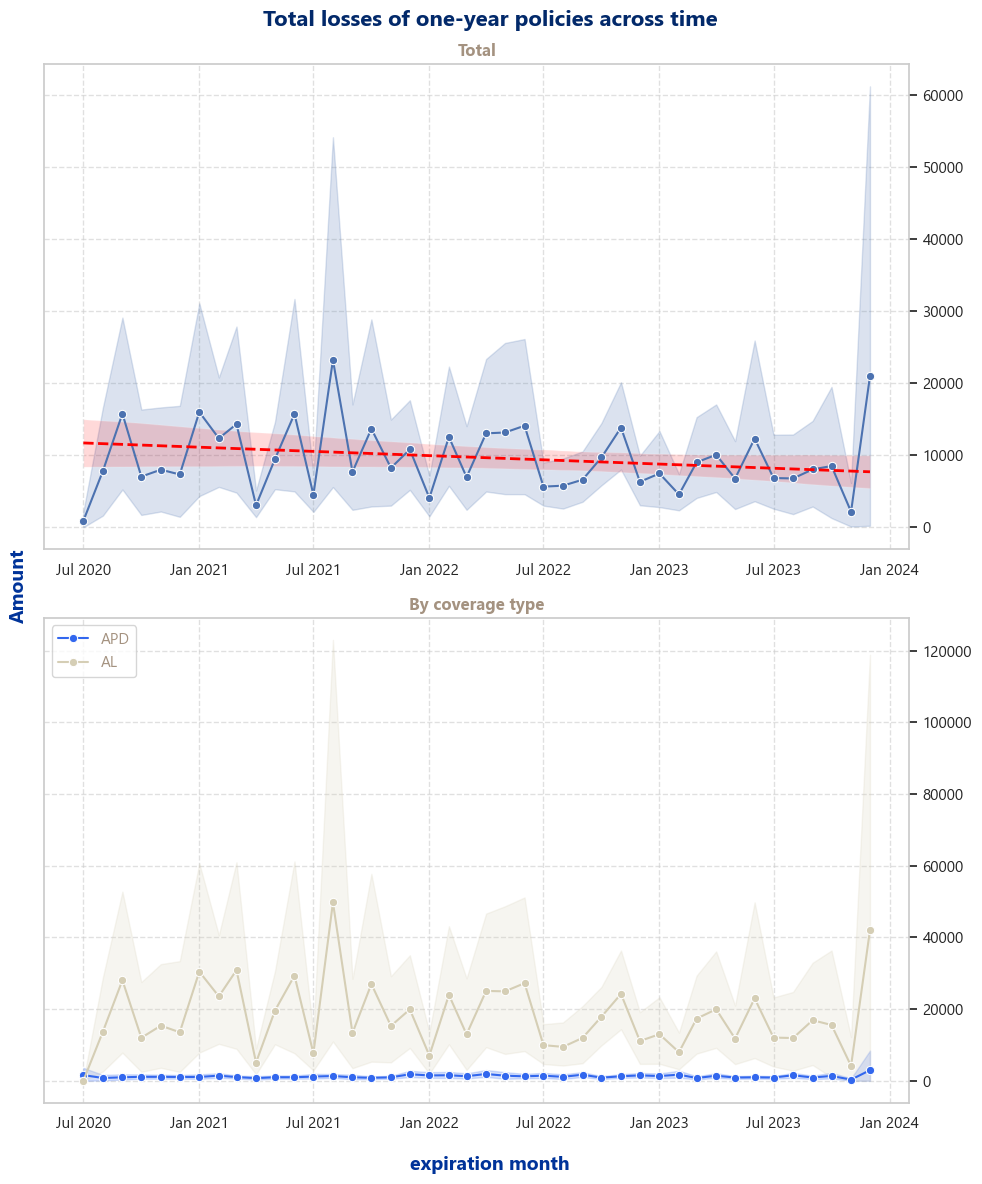

In [72]:
df_train_auto_policies['policy_expiration_date_year_month_period'] = df_train_auto_policies['policy_expiration_date_year_month_period'].dt.to_timestamp()

min_date_complete = df_train_auto_policies["policy_expiration_date_year_month_period"].min()
max_date_complete = df_train_auto_policies["policy_expiration_date_year_month_period"].max()

fig, ax = plt.subplots(2, 1, figsize=(10, 12))

sns.lineplot(data = df_train_auto_policies, x="policy_expiration_date_year_month_period", 
             y="total_loss_amount", ax=ax[0], marker="o")
sns.regplot(
    x=mdates.date2num(df_train_auto_policies["policy_expiration_date_year_month_period"]),
    y=df_train_auto_policies["total_loss_amount"],
    ax=ax[0],
    scatter=False,
    color="red",
    label="Trendline",
    line_kws={"linestyle": "--", "linewidth": 2}
)
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[0].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax[0].tick_params(axis='x', rotation=0) 
ax[0].set_xlabel('')
ax[0].set_ylabel('')
ax[0].set_title("Total",fontsize=12, fontweight='bold', color = '#A49280')
ax[0].grid(True, linestyle="--", alpha = 0.6)
ax[0].yaxis.tick_right()


sns.lineplot(data = df_train_auto_policies, x="policy_expiration_date_year_month_period", 
             y="total_loss_amount", hue="coverage_type",palette= category_colors, ax=ax[1], marker="o")

ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax[1].tick_params(axis='x', rotation=0) 
#ax[1].set_xlim(min_date_complete, max_date_complete)
ax[1].set_xlabel('')
ax[1].set_ylabel('')
ax[1].set_title("By coverage type",fontsize=12, fontweight='bold', color = '#A49280')
ax[1].grid(True, linestyle="--", alpha = 0.6)
ax[1].yaxis.tick_right()

fig.suptitle("Total losses of one-year policies across time", fontsize=16, fontweight='bold', color = '#02296A')
fig.supxlabel("expiration month", fontsize=14 ,fontweight='bold', color = '#003399')
fig.supylabel("Amount", fontsize=14, fontweight='bold', color = '#003399')


plt.legend()
plt.tight_layout()

plt.show()


In [73]:

print(f_regression(df_train_auto_policies[["claim_count"]], df_train_auto_policies["avg_loss"]))
print(mutual_info_regression(df_train_auto_policies[["claim_count"]], df_train_auto_policies["avg_loss"]))


df_train_auto_policies_claims_only = df_train_auto_policies[df_train_auto_policies['had_claim_binary'] >= 1].copy()
print(f_regression(df_train_auto_policies_claims_only[["claim_count"]], df_train_auto_policies_claims_only["avg_loss"]))
print(mutual_info_regression(df_train_auto_policies_claims_only[["claim_count"]], df_train_auto_policies_claims_only["avg_loss"]))

df_train_auto_policies_claims_only


(array([1306.20832839]), array([2.52185313e-274]))
[0.36756005]
(array([7.00655383]), array([0.00819002]))
[0.02682289]


,policy_id,insured_id,snapshot_date,coverage_type,vehicle_count,vehicle_avg_age,driver_count,driver_avg_age,years_in_business,prior_year_mileage_000,...,claim_status_current_period,days_to_first_claim_report,policy_expiration_date_year_month_numeric,policy_expiration_date_year_month_period,policy_effective_date_year_month_numeric,policy_effective_date_year_month_period,had_claim_binary,avg_loss,had_claim_binary_0,had_claim_binary_1
8,POL-004915,INS-03683,2022-05-01,APD,12,2.9000000000,9,42.2000000000,3.0000000000,268.5000000000,...,Closed,45.0000000000,2023.2500000000,2023-04-01,2022.2500000000,2022-04,1,24730.5400000000,False,True
29,POL-001492,INS-01554,2021-06-20,APD,10,10.6000000000,10,37.5000000000,3.2000000000,204.0000000000,...,Open,41.0000000000,2022.2500000000,2022-04-01,2021.2500000000,2021-04,1,10090.2800000000,False,True
33,POL-000543,INS-01234,2020-08-01,APD,13,4.2000000000,3,40.0000000000,10.3000000000,267.1000000000,...,Under Review,46.0000000000,2021.0833333333,2021-02-01,2020.0833333333,2020-02,1,1178.8800000000,False,True
35,POL-002406,INS-00370,2022-06-26,APD,12,0.0000000000,5,37.8000000000,1.0000000000,350.6000000000,...,Open,37.0000000000,2023.3333333333,2023-05-01,2022.3333333333,2022-05,1,5882.8000000000,False,True
39,POL-012175,INS-02106,2021-03-18,AL,3,7.3000000000,5,51.8000000000,3.2000000000,45.0000000000,...,Closed,54.0000000000,2021.9166666667,2021-12-01,2020.9166666667,2020-12,1,35251.6400000000,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15017,POL-005394,INS-00024,2022-06-16,APD,9,2.1000000000,5,44.7000000000,1.4000000000,284.7000000000,...,Under Review,51.0000000000,2023.0833333333,2023-02-01,2022.0833333333,2022-02,1,18360.1500000000,False,True
15045,POL-003386,INS-02613,2020-09-27,APD,7,7.0000000000,3,49.5000000000,3.7000000000,206.5000000000,...,Closed,51.0000000000,2021.3333333333,2021-05-01,2020.3333333333,2020-05,1,2319.0500000000,False,True
15048,POL-006421,INS-00968,2021-11-17,APD,10,5.6000000000,7,36.8000000000,9.3000000000,292.0000000000,...,Under Review,33.0000000000,2022.6666666667,2022-09-01,2021.6666666667,2021-09,1,1901.8300000000,False,True
15060,POL-011637,INS-03479,2020-05-12,AL,9,2.3000000000,8,41.2000000000,9.2000000000,618.6000000000,...,Open,38.0000000000,2021.1666666667,2021-03-01,2020.1666666667,2020-03,1,117343.7900000000,False,True


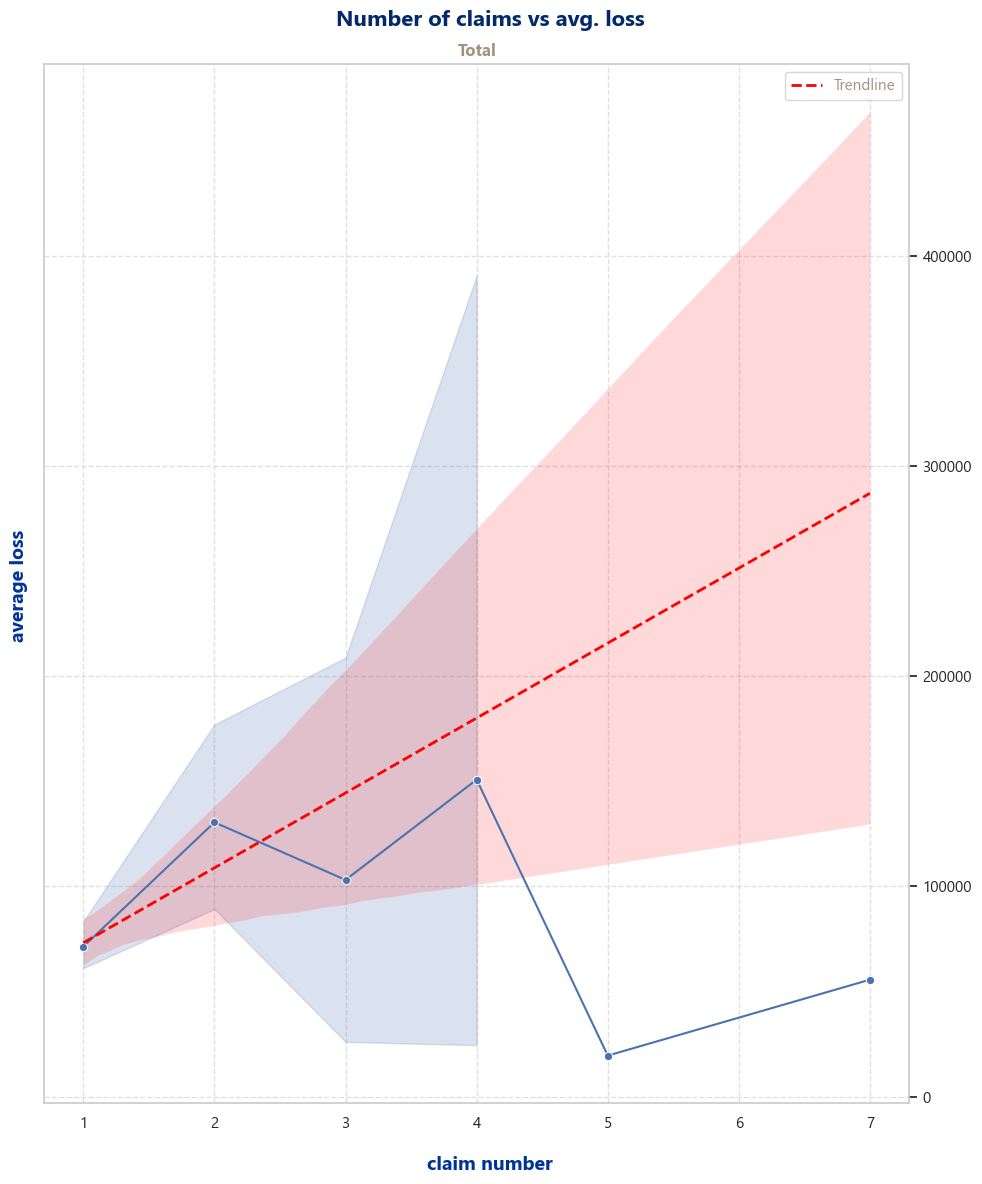

In [74]:

fig, ax = plt.subplots(1, 1, figsize=(10, 12))

sns.lineplot(data = df_train_auto_policies_claims_only, x="claim_count", y="avg_loss", marker="o")
sns.regplot(
    data = df_train_auto_policies_claims_only,
    x="claim_count",
    y=df_train_auto_policies_claims_only["avg_loss"],
    scatter=False,
    color="red",
    label="Trendline",
    line_kws={"linestyle": "--", "linewidth": 2}
)
ax.tick_params(axis='x', rotation=0) 
#ax[0].set_xlim(min_date_complete, max_date_complete)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title("Total",fontsize=12, fontweight='bold', color = '#A49280')
ax.grid(True, linestyle="--", alpha = 0.6)
ax.yaxis.tick_right()


fig.suptitle("Number of claims vs avg. loss", fontsize=16, fontweight='bold', color = '#02296A')
fig.supxlabel("claim number", fontsize=14 ,fontweight='bold', color = '#003399')
fig.supylabel("average loss", fontsize=14, fontweight='bold', color = '#003399')


plt.legend()
plt.tight_layout()

plt.show()

<Axes: xlabel='claim_count', ylabel='avg_loss'>

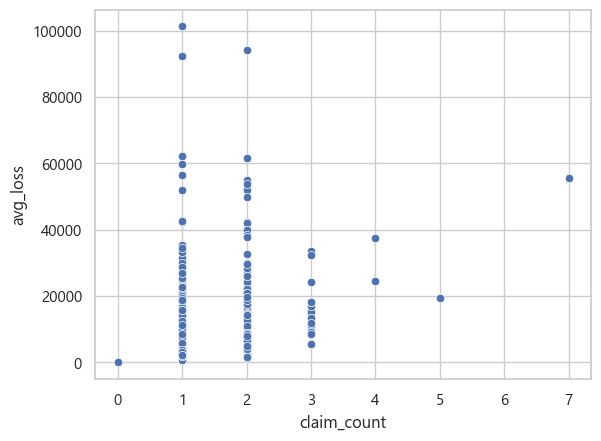

In [75]:
# this plots won't be included in the presentation but were neded to check the reltion between the claim count and avg. loss
sns.scatterplot(data=df_train_auto_policies[df_train_auto_policies['coverage_type'] == 'APD'], x="claim_count", y="avg_loss")

<Axes: xlabel='claim_count', ylabel='avg_loss'>

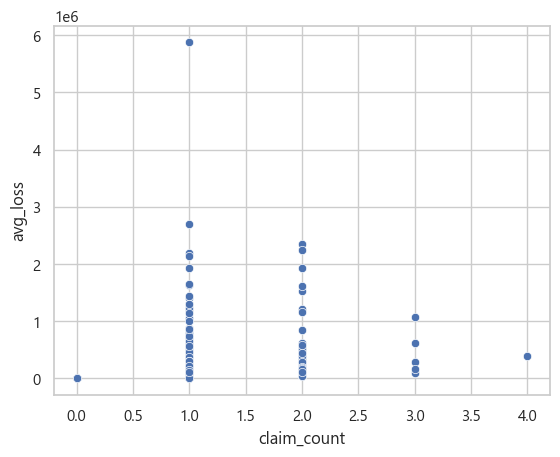

In [76]:
sns.scatterplot(data=df_train_auto_policies[df_train_auto_policies['coverage_type'] == 'AL'], x="claim_count", y="avg_loss")

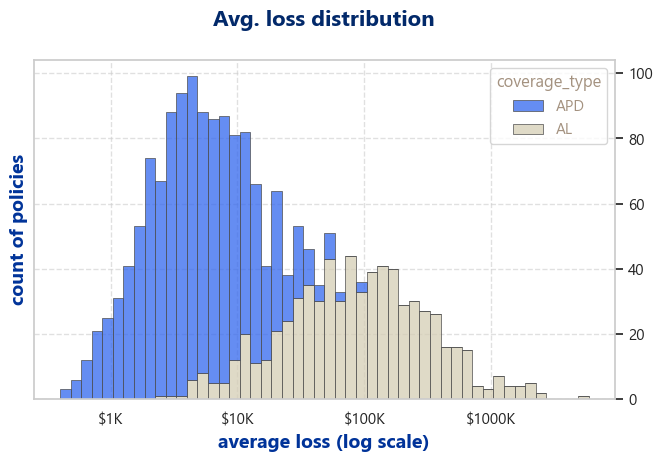

In [77]:
# we will try to figure both the distribution of the average loss 
# and the number of claims for each coverage type

fig, ax = plt.subplots(figsize=(7, 5))

sns.histplot(
    df_train_auto_policies,
    x="avg_loss", hue="coverage_type",
    multiple="stack",
    palette=category_colors,
    edgecolor=".3",
    linewidth=.5,
    log_scale=True,
    bins=50
)

ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_xticks([1000, 10000, 100000, 1000000])

#Format trick generated w/ Gemini
ax.get_xaxis().set_major_formatter(
    FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}')
)
ax.yaxis.tick_right()
ax.grid(True, linestyle="--", alpha = 0.6)
plt.xlabel('average loss (log scale)',fontsize=14,fontweight='bold', color='#003399')
plt.ylabel('count of policies',fontsize=14,fontweight='bold', color='#003399')
plt.title('Avg. loss distribution', y=1.04, fontsize=16, pad=15, fontweight='bold', color='#02296A')

plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
plt.show()

In [78]:
#we will test for log normality on both coverage types
df_al_log = df_train_auto_policies[(df_train_auto_policies['coverage_type'] == 'AL') 
                                   & (df_train_auto_policies['avg_loss'] > 0)].copy()
df_apd_log = df_train_auto_policies[(df_train_auto_policies['coverage_type'] == 'APD') 
                                   & (df_train_auto_policies['avg_loss'] > 0)].copy()

df_al_log['avg_loss_log'] = np.log(df_al_log['avg_loss'])
df_apd_log['avg_loss_log'] = np.log(df_apd_log['avg_loss'])

log_normal_test_al = stats.normaltest(df_al_log['avg_loss_log'], axis=0)
print(log_normal_test_al)

log_normal_test_apd = stats.normaltest(df_apd_log['avg_loss_log'], axis=0)
print(log_normal_test_apd)

NormaltestResult(statistic=np.float64(0.37849925826274605), pvalue=np.float64(0.8275798928575944))
NormaltestResult(statistic=np.float64(7.109212574852084), pvalue=np.float64(0.028592629978451124))


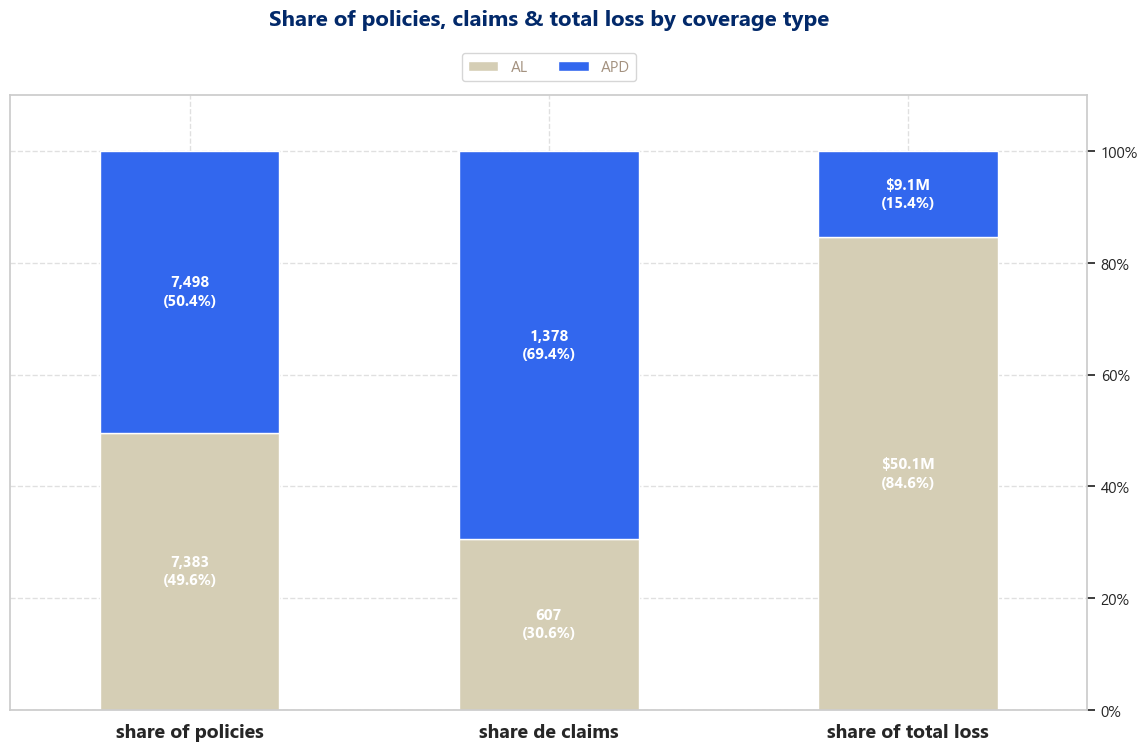

In [79]:
# the unbalance is significative enough to merit further analysis,
# lets see its true size

#we will proceed by eliminating outliers based on avg. loss, using 3 stds as our z score filter

z_scores_total_loss = np.abs(stats.zscore(df_train_auto_policies['avg_loss']))
threshold_z = 3

outlier_indices = df_train_auto_policies.index[z_scores_total_loss > threshold_z]
no_outliers = df_train_auto_policies.drop(outlier_indices)

#generated with Gemini, modified by me to match the desing of the other plots

rows_pct = no_outliers['coverage_type'].value_counts(normalize=True) * 100
amount_sum = no_outliers.groupby('coverage_type')['total_loss_amount'].sum()
amount_pct = (amount_sum / amount_sum.sum()) * 100
claims_sum = no_outliers.groupby('coverage_type')['claim_count'].sum()
claims_pct = (claims_sum / claims_sum.sum()) * 100

summary_df = pd.DataFrame({
    'share of policies': rows_pct,
    'share de claims': claims_pct,
    'share of total loss': amount_pct
}).T 

rows_net = no_outliers['coverage_type'].value_counts()
summary_net = pd.DataFrame({
    'share of policies': rows_net,
    'share de claims': claims_sum,
    'share of total loss': amount_sum
}).T

ax = summary_df.plot(
    kind='bar', 
    stacked=True, 
    figsize=(12, 8), 
    color=category_colors,
    width=0.5
)
ax.yaxis.tick_right()

def format_net_value(value, metric_name):
    if 'loss' in metric_name:  
        if value >= 1e6: return f"${value/1e6:.1f}M"
        if value >= 1e3: return f"${value/1e3:.0f}K"
        return f"${value:.0f}"
    return f"{int(value):,}" 

categories = summary_df.columns

for i, container in enumerate(ax.containers):
    category_name = categories[i]
    labels = []
    
    for row_idx, rect in enumerate(container):
        pct_value = rect.get_height()
        if pct_value > 3:  
            metric_name = summary_df.index[row_idx]
            net_value = summary_net.loc[metric_name, category_name]
            
            formatted_net = format_net_value(net_value, metric_name)
            labels.append(f'{formatted_net}\n({pct_value:.1f}%)')
        else:
            labels.append('')
            
    ax.bar_label(container, labels=labels, label_type='center', fontsize=11, weight='bold', color='white')

ax.grid(True, linestyle="--", alpha=0.6)

plt.xlabel('')
plt.ylabel('')
plt.xticks(
    rotation=0, 
    fontsize=14,
    fontweight='bold',
)
plt.ylim(0, 110)

ax.yaxis.set_major_formatter('{x:1.0f}%')

plt.legend(bbox_to_anchor=(0.5, 1.01), loc="lower center", ncols=2)
plt.title('Share of policies, claims & total loss by coverage type', y=1.08, fontsize=16, pad=15, fontweight='bold', color='#02296A')

plt.tight_layout(rect=[0.03, 0.02, 1, 0.98])
plt.show()

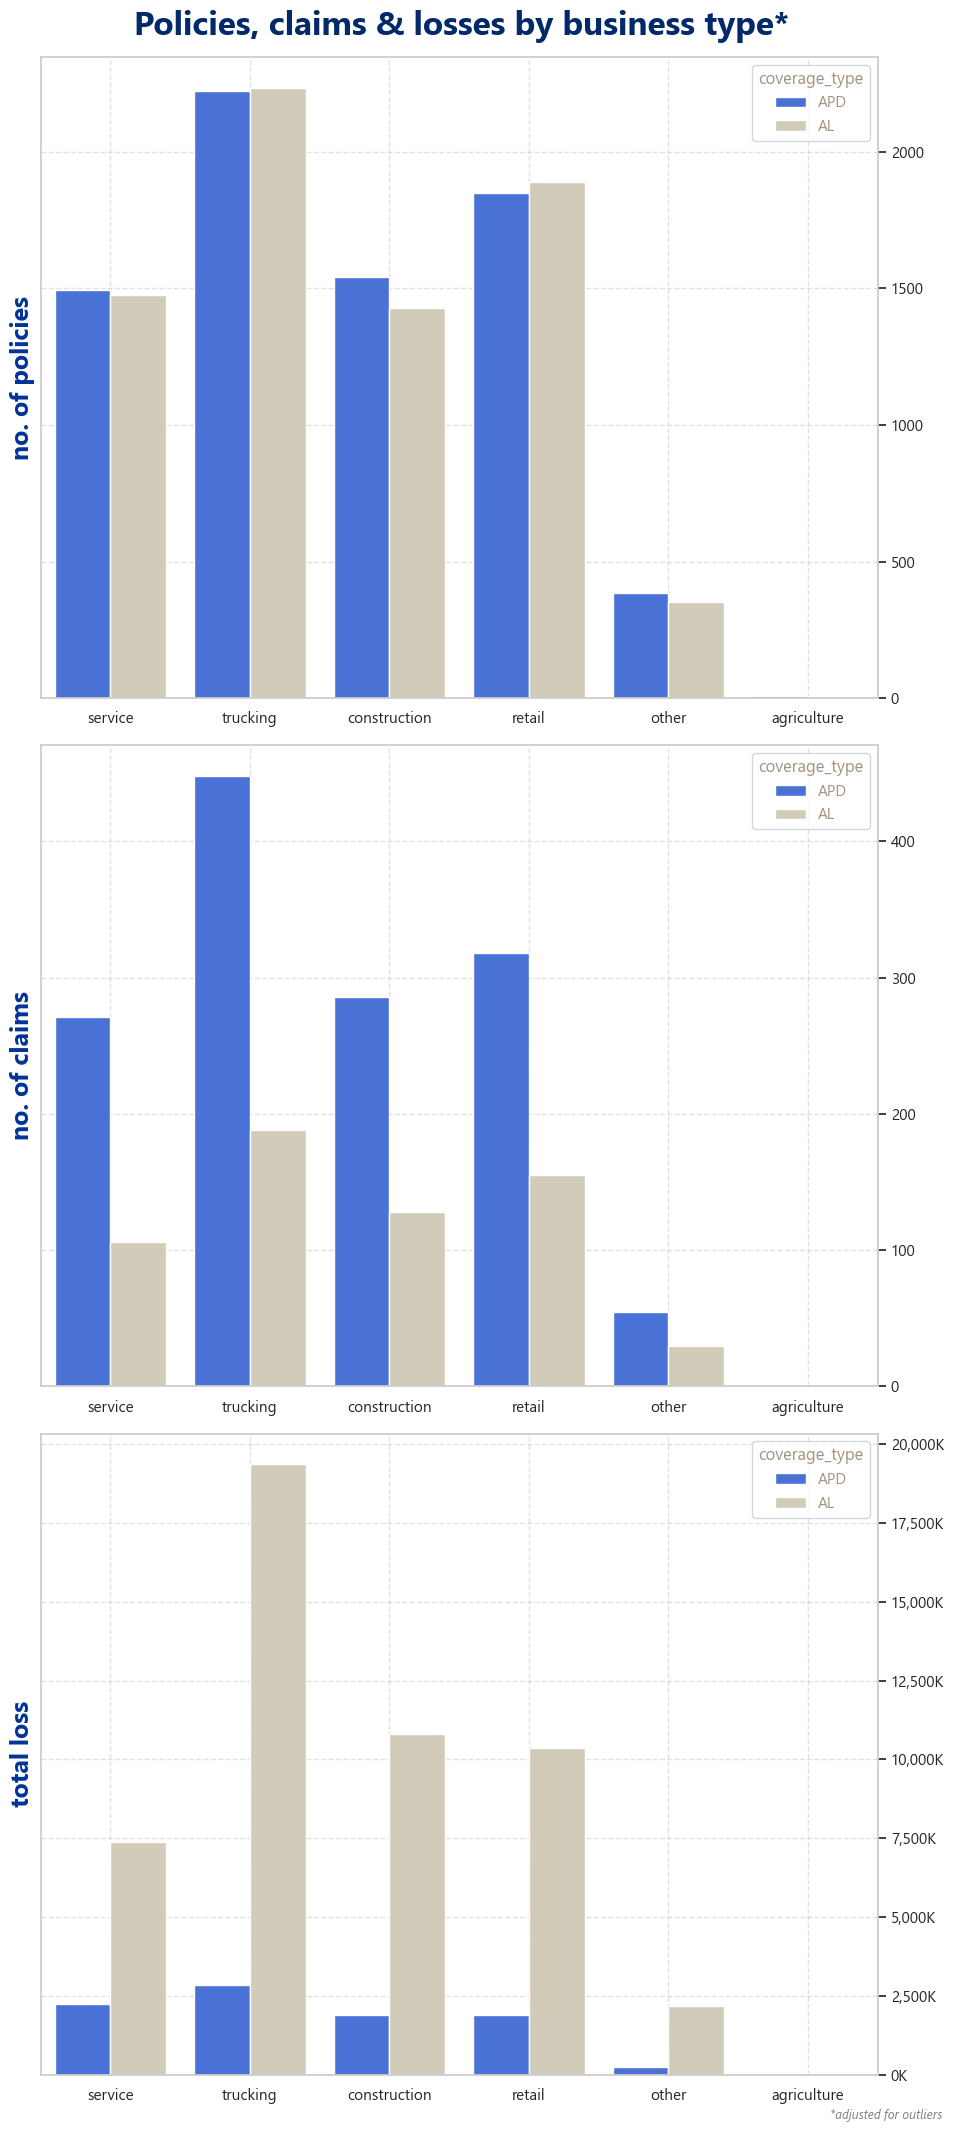

In [80]:
#AL accounts for only 31% of the claims but 85% of the total loss, 
# we will need to take that into account later

fig, ax = plt.subplots(3, 1, figsize=(10, 22))

sns.countplot(no_outliers, x="business_type", 
            hue="coverage_type",palette= category_colors, ax=ax[0])
ax[0].set_xlabel('')
ax[0].set_ylabel('no. of policies', fontsize=18, fontweight='bold', color = '#003399')
ax[0].grid(True, linestyle="--", alpha = 0.6)
ax[0].yaxis.tick_right()

sns.barplot(no_outliers, x="business_type", y="claim_count", 
            hue="coverage_type",palette= category_colors, ax=ax[1],estimator=sum, errorbar=None)
ax[1].set_xlabel('')
ax[1].set_ylabel('no. of claims', fontsize=18, fontweight='bold', color = '#003399')
ax[1].grid(True, linestyle="--", alpha = 0.6)
ax[1].yaxis.tick_right()

sns.barplot(no_outliers, x="business_type", y="total_loss_amount", 
            hue="coverage_type",palette= category_colors, ax=ax[2],estimator=sum, errorbar=None)
ax[2].set_xlabel('')
ax[2].yaxis.set_major_formatter(formatter_money_ammounts)
ax[2].set_ylabel('total loss', fontsize=18, fontweight='bold', color = '#003399')
ax[2].grid(True, linestyle="--", alpha = 0.6)
ax[2].yaxis.tick_right()

fig.suptitle("Policies, claims & losses by business type*", fontsize=24, fontweight='bold', color = '#02296A')
plt.tight_layout(rect=[0.03, 0.02, 1, 0.99])
fig.text(
    0.98,
    0.02,
    "*adjusted for outliers",
    transform=fig.transFigure,
    horizontalalignment="right",
    verticalalignment="bottom",
    fontsize=9,
    color="gray",
    style='italic'
)


plt.show()

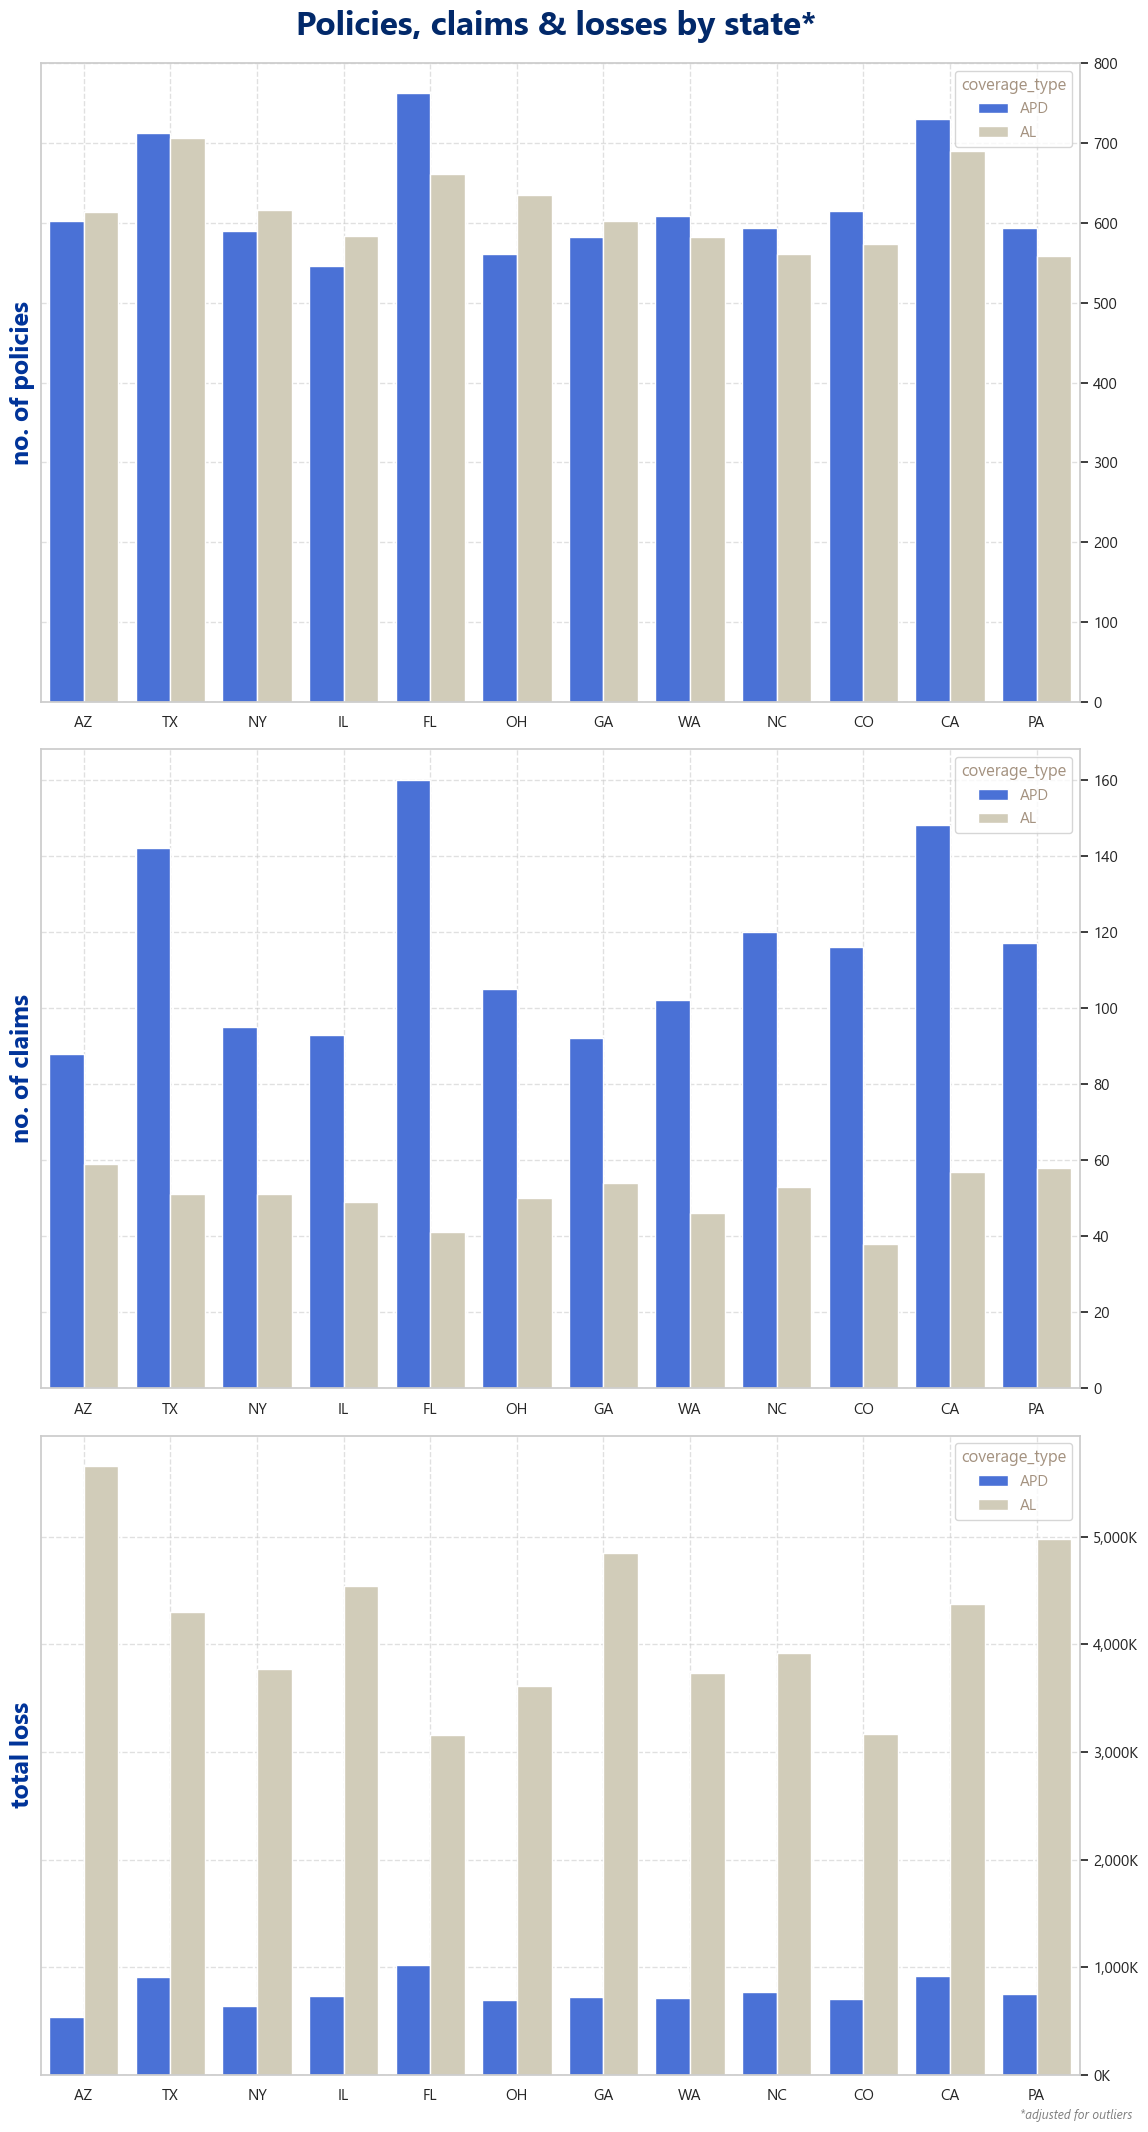

In [81]:
z_scores_total_loss = np.abs(stats.zscore(df_train_auto_policies['avg_loss']))
threshold_z = 3

outlier_indices = df_train_auto_policies.index[z_scores_total_loss > threshold_z]
no_outliers = df_train_auto_policies.drop(outlier_indices)

fig, ax = plt.subplots(3, 1, figsize=(12, 22))

sns.countplot(no_outliers, x="state", 
            hue="coverage_type",palette= category_colors, ax=ax[0])
ax[0].set_xlabel('')
ax[0].set_ylabel('no. of policies', fontsize=18, fontweight='bold', color = '#003399')
ax[0].grid(True, linestyle="--", alpha = 0.6)
ax[0].yaxis.tick_right()

sns.barplot(no_outliers, x="state", y="claim_count", 
            hue="coverage_type",palette= category_colors, ax=ax[1],estimator=sum, errorbar=None)
ax[1].set_xlabel('')
ax[1].set_ylabel('no. of claims', fontsize=18, fontweight='bold', color = '#003399')
ax[1].grid(True, linestyle="--", alpha = 0.6)
ax[1].yaxis.tick_right()

sns.barplot(no_outliers, x="state", y="total_loss_amount", 
            hue="coverage_type",palette= category_colors, ax=ax[2],estimator=sum, errorbar=None)
ax[2].set_xlabel('')
ax[2].yaxis.set_major_formatter(formatter_money_ammounts)
ax[2].set_ylabel('total loss', fontsize=18, fontweight='bold', color = '#003399')
ax[2].grid(True, linestyle="--", alpha = 0.6)
ax[2].yaxis.tick_right()

fig.suptitle("Policies, claims & losses by state*", fontsize=24, fontweight='bold', color = '#02296A')
plt.tight_layout(rect=[0.03, 0.02, 1, 0.99])
fig.text(
    0.98,
    0.02,
    "*adjusted for outliers",
    transform=fig.transFigure,
    horizontalalignment="right",
    verticalalignment="bottom",
    fontsize=9,
    color="gray",
    style='italic'
)


plt.show()

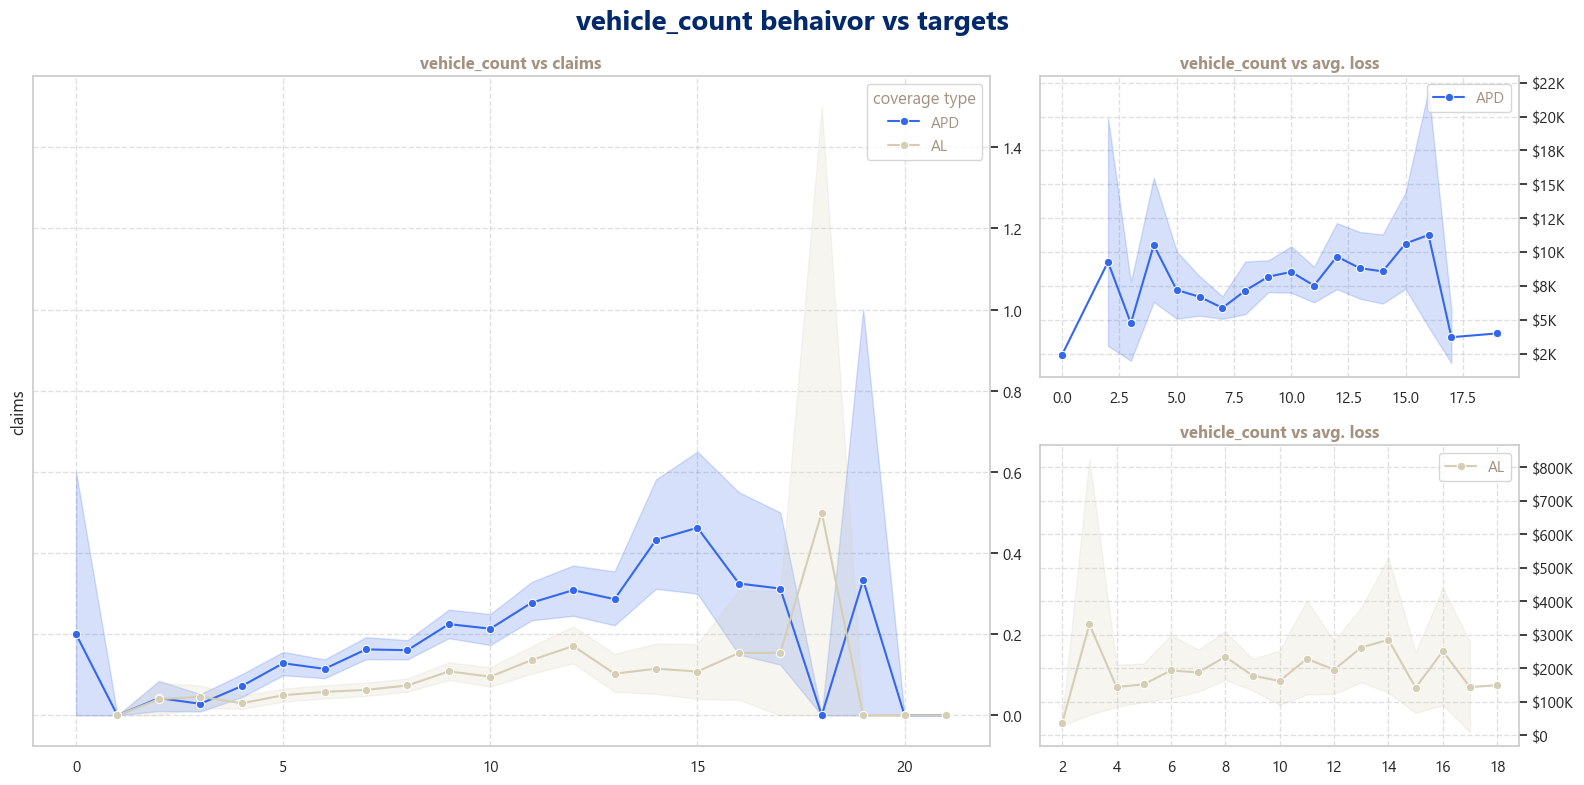

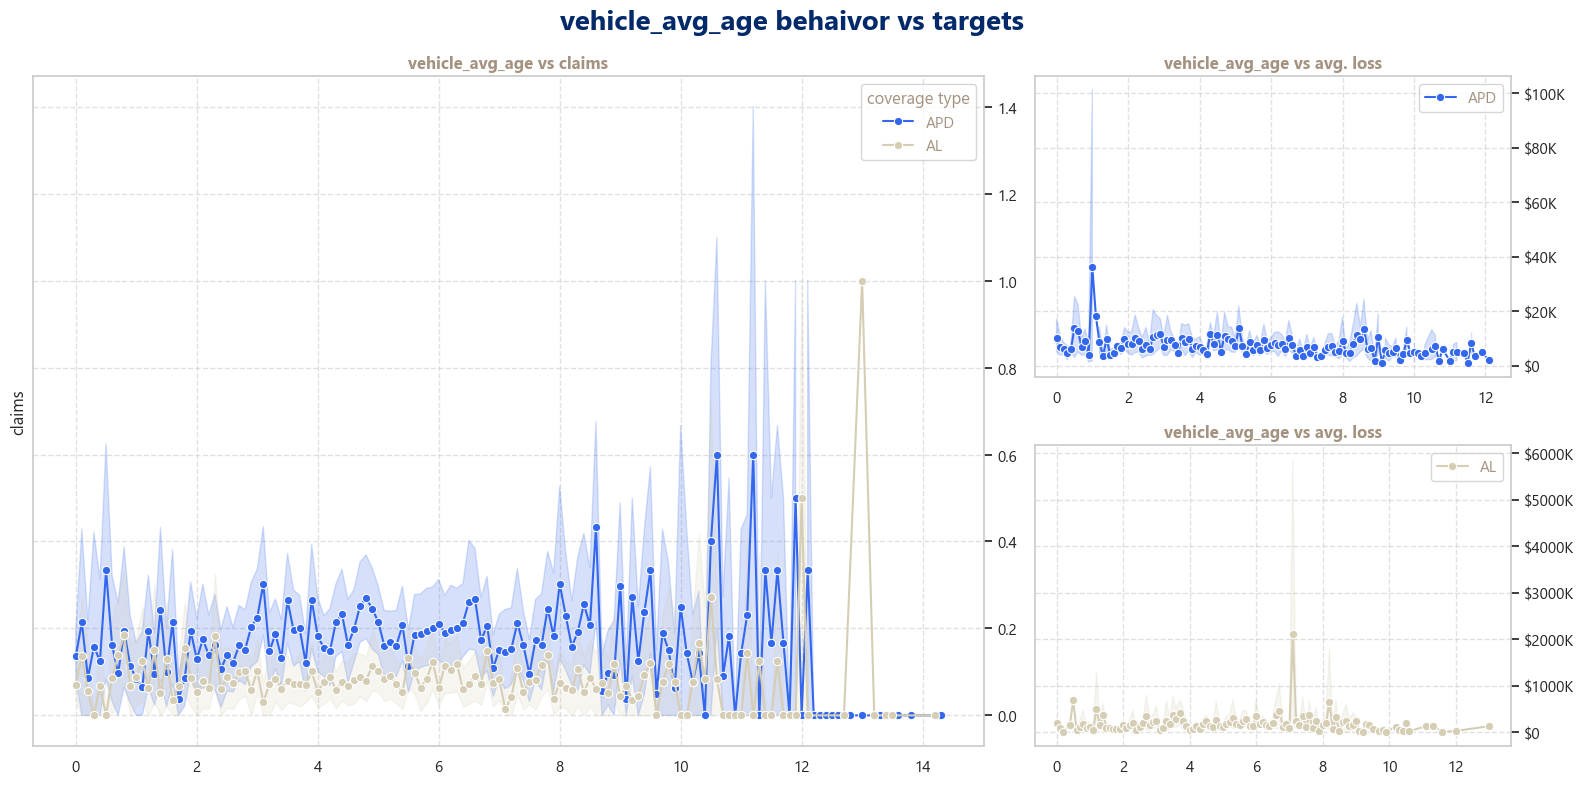

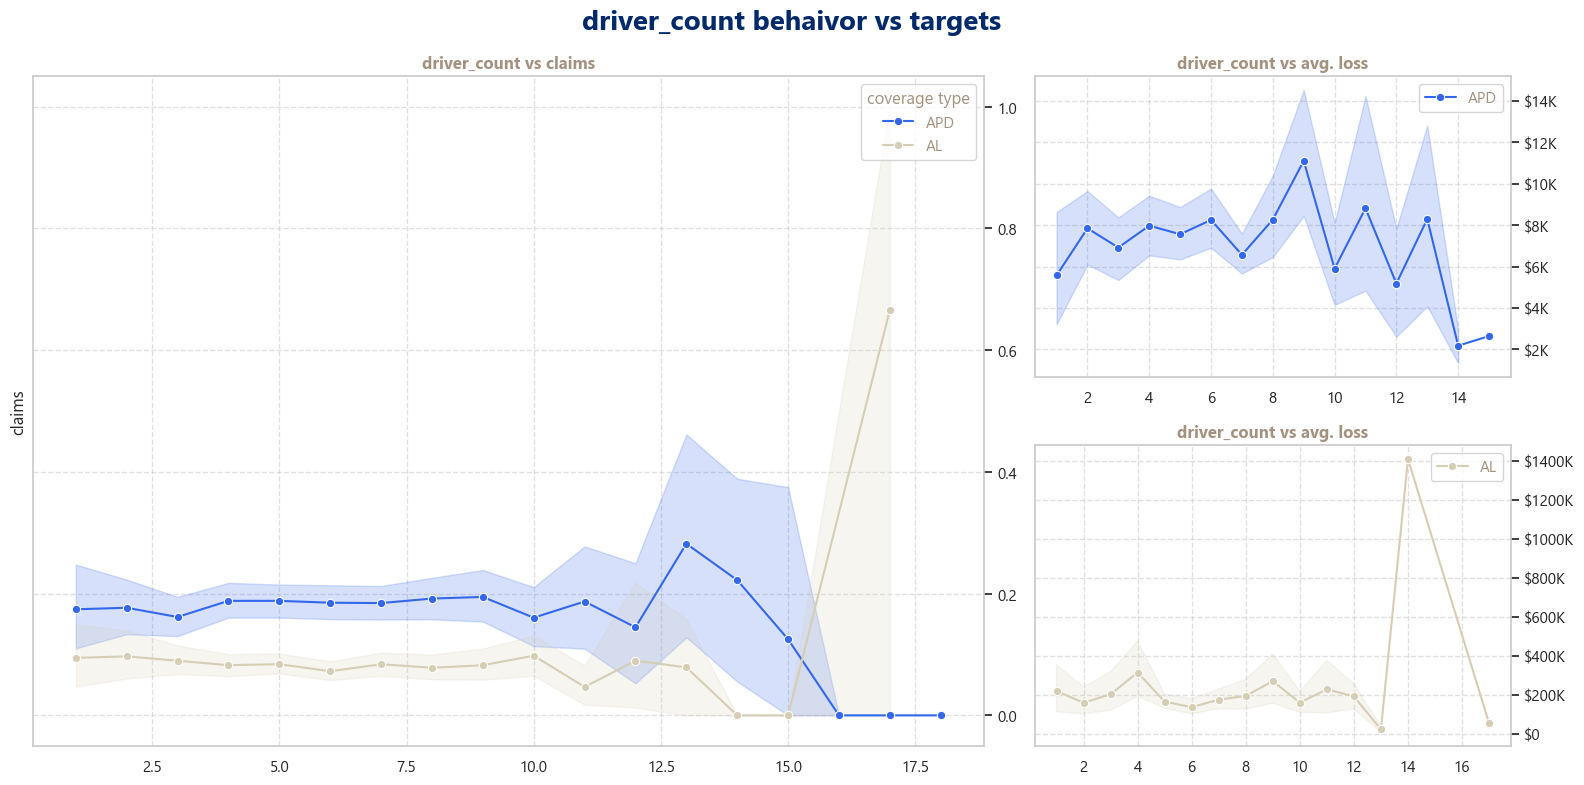

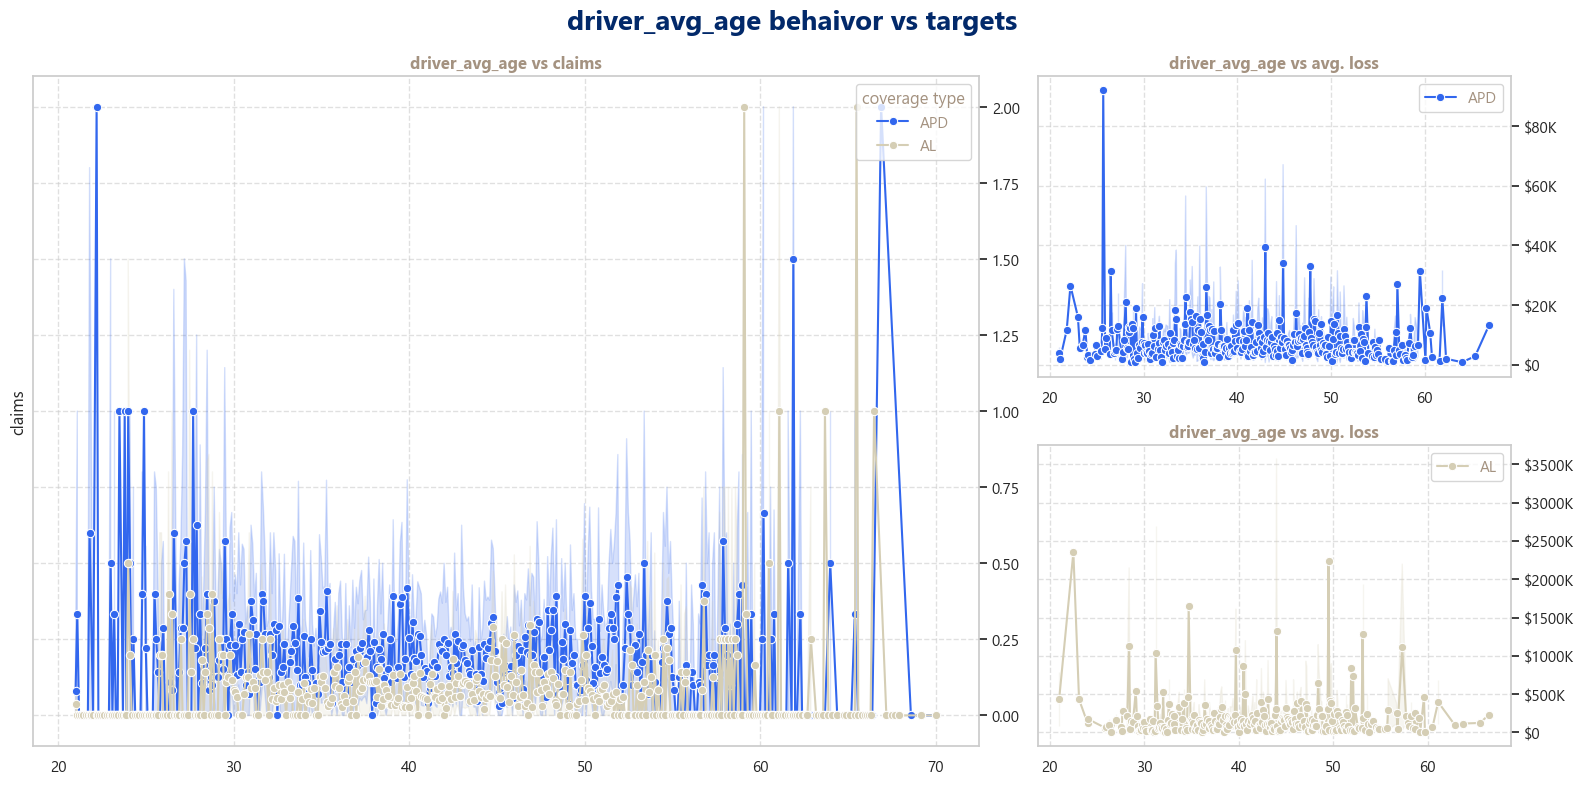

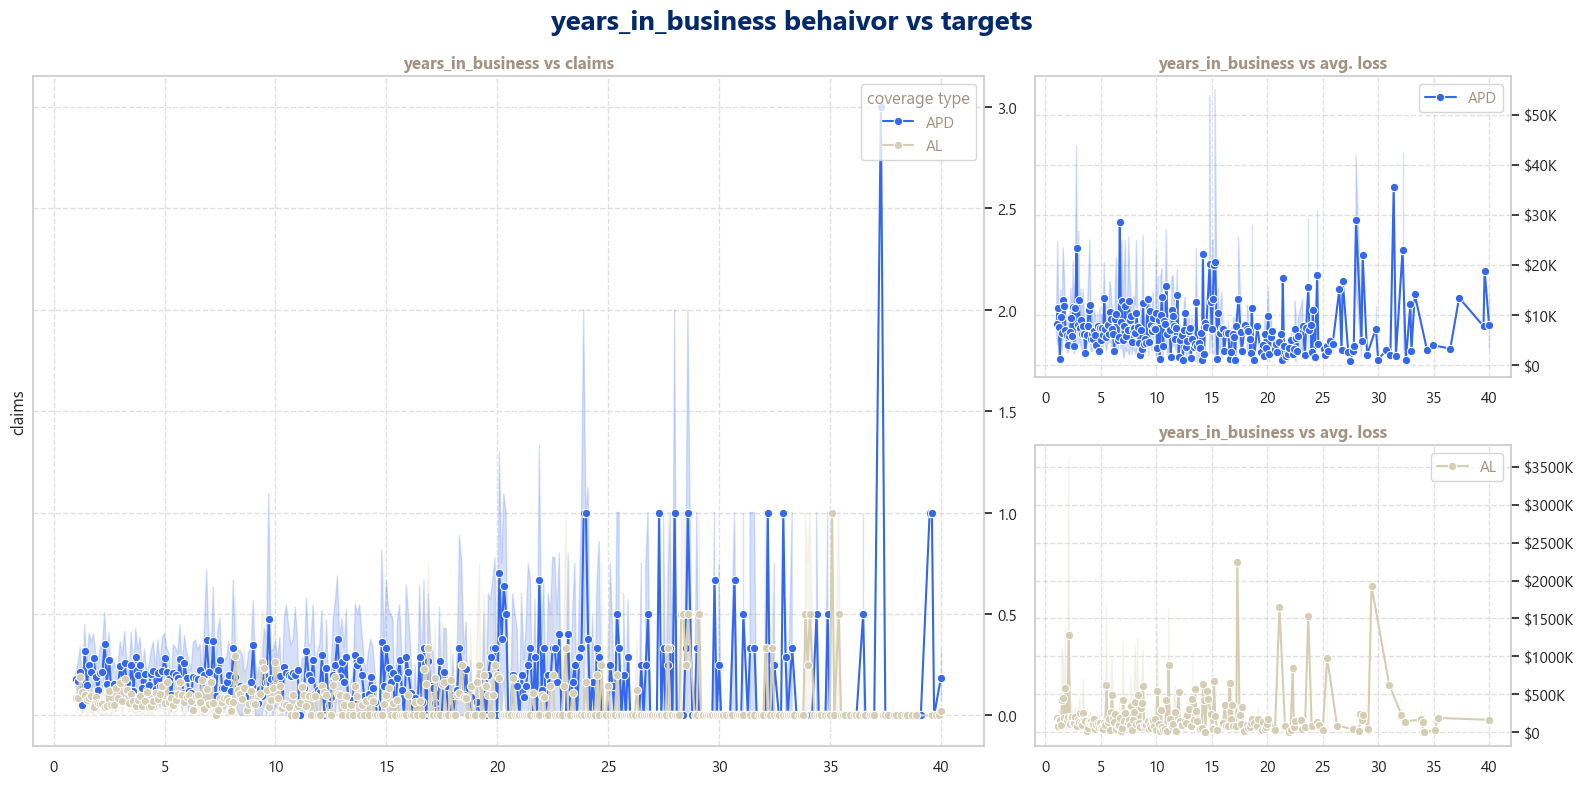

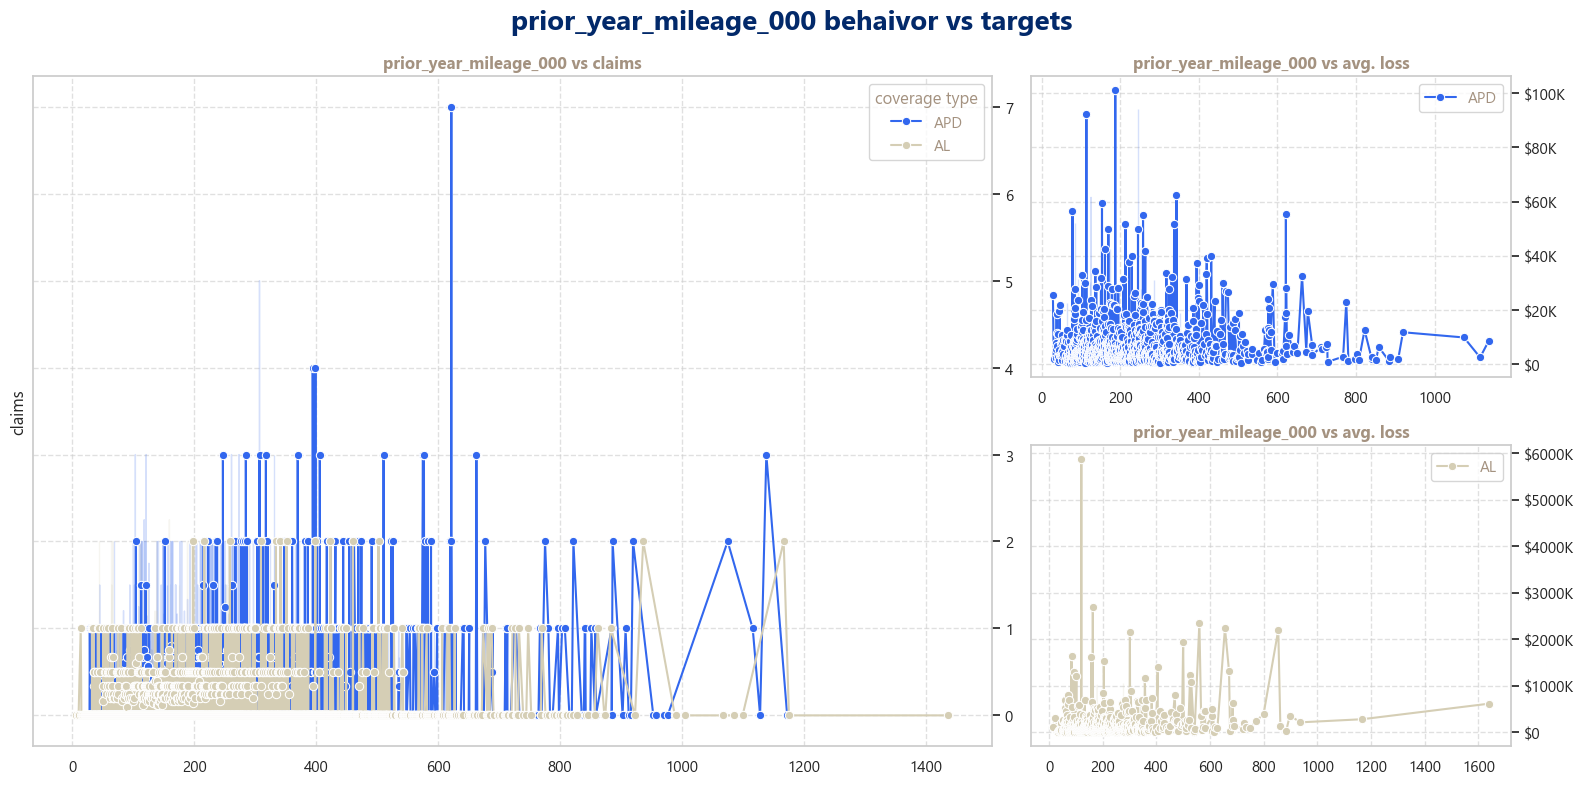

In [86]:
#now we want to understand the relationship between the remainig features and our targets

features = ['vehicle_count','vehicle_avg_age','driver_count','driver_avg_age','years_in_business','prior_year_mileage_000']

for feature in features:
    if feature in ['vehicle_count','driver_count']:
        layout = [
        ["Left", "TopRight"],
        ["Left", "BottomRight"],
        ]

        fig, axs = plt.subplot_mosaic(layout, gridspec_kw={"width_ratios": [2, 1]}, figsize=(16, 8))

        sns.lineplot(data = df_train_auto_policies_claims_only[df_train_auto_policies_claims_only["coverage_type"] == 'APD'], x= feature, 
                    y="avg_loss",hue="coverage_type",palette= category_colors, ax=axs["TopRight"], marker="o")
        axs["TopRight"].tick_params(axis='x', rotation=0) 
        axs["TopRight"].set_xlabel('')
        axs["TopRight"].set_ylabel('')
        axs["TopRight"].set_title(f"{feature} vs avg. loss",fontsize=12, fontweight='bold', color = '#A49280')
        axs["TopRight"].grid(True, linestyle="--", alpha = 0.6)
        axs["TopRight"].yaxis.tick_right()
        axs["TopRight"].legend(loc='upper right', frameon=True, title=None)
        # axs["TopRight"].set_yscale('log')
        # axs["TopRight"].yaxis.set_major_formatter(ScalarFormatter())
        # axs["TopRight"].set_yticks([1000, 10000, 100000, 1000000])

        # #Format trick generated w/ Gemini
        axs["TopRight"].get_yaxis().set_major_formatter(
            FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}')
        )

        sns.lineplot(data = df_train_auto_policies_claims_only[df_train_auto_policies_claims_only["coverage_type"] == 'AL'], x= feature, 
                    y="avg_loss",hue="coverage_type",palette= category_colors, ax=axs["BottomRight"], marker="o")
        axs["BottomRight"].tick_params(axis='x', rotation=0) 
        axs["BottomRight"].set_xlabel('')
        axs["BottomRight"].set_ylabel('')
        axs["BottomRight"].set_title(f"{feature} vs avg. loss",fontsize=12, fontweight='bold', color = '#A49280')
        axs["BottomRight"].grid(True, linestyle="--", alpha = 0.6)
        axs["BottomRight"].yaxis.tick_right()
        axs["BottomRight"].legend(loc='upper right', frameon=True, title=None)
        # axs["BottomRight"].set_yscale('log')
        # axs["BottomRight"].yaxis.set_major_formatter(ScalarFormatter())
        # axs["BottomRight"].set_yticks([1000, 10000, 100000, 1000000])

        # #Format trick generated w/ Gemini
        axs["BottomRight"].get_yaxis().set_major_formatter(
            FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}')
        )



        sns.lineplot(data = no_outliers, x=feature, 
                    y="claim_count", hue="coverage_type",palette= category_colors, ax=axs["Left"], marker="o")
        axs["Left"].tick_params(axis='x', rotation=0) 
        axs["Left"].set_xlabel('')
        axs["Left"].set_ylabel('claims')
        axs["Left"].set_title(f"{feature} vs claims",fontsize=12, fontweight='bold', color = '#A49280')
        axs["Left"].grid(True, linestyle="--", alpha = 0.6)
        axs["Left"].yaxis.tick_right()
        axs["Left"].legend(loc='upper right', frameon=True,title='coverage type')

        fig.suptitle(f"{feature} behaivor vs targets", fontsize=20, fontweight='bold', color = '#02296A')

    else:
        layout = [
        ["Left", "TopRight"],
        ["Left", "BottomRight"],
        ]

        fig, axs = plt.subplot_mosaic(layout, gridspec_kw={"width_ratios": [2, 1]}, figsize=(16, 8))

        sns.lineplot(data = df_train_auto_policies_claims_only[df_train_auto_policies_claims_only["coverage_type"] == 'APD'], x= feature, 
                    y="avg_loss",hue="coverage_type",palette= category_colors, ax=axs["TopRight"], marker="o")
        axs["TopRight"].tick_params(axis='x', rotation=0) 
        axs["TopRight"].set_xlabel('')
        axs["TopRight"].set_ylabel('')
        axs["TopRight"].set_title(f"{feature} vs avg. loss",fontsize=12, fontweight='bold', color = '#A49280')
        axs["TopRight"].grid(True, linestyle="--", alpha = 0.6)
        axs["TopRight"].yaxis.tick_right()
        axs["TopRight"].legend(loc='upper right', frameon=True, title=None)
        # axs["TopRight"].set_yscale('log')
        # axs["TopRight"].yaxis.set_major_formatter(ScalarFormatter())
        # axs["TopRight"].set_yticks([1000, 10000, 100000, 1000000])

        # #Format trick generated w/ Gemini
        axs["TopRight"].get_yaxis().set_major_formatter(
            FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}')
        )

        sns.lineplot(data = df_train_auto_policies_claims_only[df_train_auto_policies_claims_only["coverage_type"] == 'AL'], x= feature, 
                    y="avg_loss",hue="coverage_type",palette= category_colors, ax=axs["BottomRight"], marker="o")
        axs["BottomRight"].tick_params(axis='x', rotation=0) 
        axs["BottomRight"].set_xlabel('')
        axs["BottomRight"].set_ylabel('')
        axs["BottomRight"].set_title(f"{feature} vs avg. loss",fontsize=12, fontweight='bold', color = '#A49280')
        axs["BottomRight"].grid(True, linestyle="--", alpha = 0.6)
        axs["BottomRight"].yaxis.tick_right()
        axs["BottomRight"].legend(loc='upper right', frameon=True, title=None)
        # axs["BottomRight"].set_yscale('log')
        # axs["BottomRight"].yaxis.set_major_formatter(ScalarFormatter())
        # axs["BottomRight"].set_yticks([1000, 10000, 100000, 1000000])

        # #Format trick generated w/ Gemini
        axs["BottomRight"].get_yaxis().set_major_formatter(
            FuncFormatter(lambda x, p: f'${x/1000:.0f}K' if x >= 1000 else f'${x:.0f}')
        )



        sns.lineplot(data = no_outliers, x=feature, 
                    y="claim_count", hue="coverage_type",palette= category_colors, ax=axs["Left"], marker="o")
        axs["Left"].tick_params(axis='x', rotation=0) 
        axs["Left"].set_xlabel('')
        axs["Left"].set_ylabel('claims')
        axs["Left"].set_title(f"{feature} vs claims",fontsize=12, fontweight='bold', color = '#A49280')
        axs["Left"].grid(True, linestyle="--", alpha = 0.6)
        axs["Left"].yaxis.tick_right()
        axs["Left"].legend(loc='upper right', frameon=True,title='coverage type')

        fig.suptitle(f"{feature} behaivor vs targets", fontsize=20, fontweight='bold', color = '#02296A')


    plt.tight_layout()

    plt.show()

In [ ]:
#now we will use prior_apd_claim_count,prior_al_claim_count 
# and prior_loss_amount to calculate the average loss per 
# coverage_type of the past period, we will use the observation 
# that the distribution of claims and loss amounts between AL and APD 
# doesn't change significantly across time,so we will asume the 
